<a href="https://colab.research.google.com/github/Aditi-Chowdhury2005/AI-ML-Project/blob/main/Different_Machine_Learning_Models_Applied_to_the_Processed_Stroke_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install imbalanced-learn -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

# Automatically read the uploaded CSV file
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset loaded successfully!
Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (5110, 11)

Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data Types:
gender                 int64
age                  float64
hypertension           int64
heart_disease          int64
ever_married           int64
work_type              int64
Residence_type         int64
avg_glucose_level    float64
bmi                  float64
smoking_status         int64
stroke                 int64
dtype: object

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Duplicate Rows: 0


In [ ]:
columns_to_drop = []

for col in df.columns:
    if col.lower() in ["id", "patient_id"]:
        columns_to_drop.append(col)

if len(columns_to_drop) > 0:
    df = df.drop(columns=columns_to_drop)
    print("Dropped columns:", columns_to_drop)

print("New Shape:", df.shape)

New Shape: (5110, 11)


In [ ]:
possible_targets = [
    "stroke",
    "target",
    "label",
    "outcome",
    "stroke_risk"
]

TARGET_COLUMN = None

for col in df.columns:
    if col.lower() in possible_targets:
        TARGET_COLUMN = col
        break

if TARGET_COLUMN is None:
    print("Available columns:")
    print(df.columns.tolist())
    raise ValueError(
        "Target column was not detected. "
        "Please set TARGET_COLUMN manually."
    )

print("Target Column:", TARGET_COLUMN)
print("\nTarget Distribution:")
print(df[TARGET_COLUMN].value_counts())

Target Column: stroke

Target Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Convert target to numeric if necessary
if y.dtype == "object":
    encoder = LabelEncoder()
    y = encoder.fit_transform(y)

# Convert categorical features to numerical using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (5110, 10)
Target shape: (5110,)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2


In [ ]:
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values after imputation:")
print(X.isnull().sum().sum())

Missing values after imputation:
0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4088
Testing samples: 1022


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
models = {

"Logistic Regression": LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
),

"Decision Tree": DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
),

"Random Forest": RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42
),

"SVM": SVC(
    probability=True,
    class_weight="balanced",
    random_state=42
),

"KNN": KNeighborsClassifier(
    n_neighbors=5
)

}

In [ ]:
results = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print("\nTraining:", name)

    # SVM, Logistic Regression and KNN use scaled data
    # Decision Tree and Random Forest can also work with
    # scaled data without any problem.
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    auc = roc_auc_score(y_test, y_prob)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC": auc
    }

    predictions[name] = y_pred
    probabilities[name] = y_prob

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))
    print("AUC      :", round(auc, 4))


Training: Logistic Regression
Accuracy : 0.7515
Precision: 0.1408
Recall   : 0.8
F1-Score : 0.2395
AUC      : 0.8387

Training: Decision Tree
Accuracy : 0.8258
Precision: 0.1768
Recall   : 0.7
F1-Score : 0.2823
AUC      : 0.8093

Training: Random Forest
Accuracy : 0.9247
Precision: 0.2128
Recall   : 0.2
F1-Score : 0.2062
AUC      : 0.8205

Training: SVM
Accuracy : 0.7358
Precision: 0.1181
Recall   : 0.68
F1-Score : 0.2012
AUC      : 0.7856

Training: KNN
Accuracy : 0.9481
Precision: 0.2
Recall   : 0.02
F1-Score : 0.0364
AUC      : 0.614


In [ ]:
# ============================================================
# 12. BUILD ARTIFICIAL NEURAL NETWORK (ANN)
# ============================================================

tf.random.set_seed(42)
np.random.seed(42)

ann = Sequential([

    Dense(
        64,
        activation="relu",
        input_shape=(X_train_scaled.shape[1],)
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# 13. TRAIN ANN
# ============================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("ANN training completed!")

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9125 - loss: 0.3121 - val_accuracy: 0.9425 - val_loss: 0.2043
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9535 - loss: 0.1739 - val_accuracy: 0.9425 - val_loss: 0.1842
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9535 - loss: 0.1628 - val_accuracy: 0.9425 - val_loss: 0.1818
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9535 - loss: 0.1654 - val_accuracy: 0.9425 - val_loss: 0.1775
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9535 - loss: 0.1641 - val_accuracy: 0.9425 - val_loss: 0.1776
Epoch 6/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9535 - loss: 0.1574 - val_accuracy: 0.9425 - val_loss: 0.1768
Epoch 7/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9535 - loss: 0.1585 - val_accuracy: 0.9425 - val_loss: 0.1752
Epoch 8/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9535 - loss: 0.1552 - val_ac

In [ ]:
# ============================================================
# 14. ANN PREDICTION
# ============================================================

ann_prob = ann.predict(
    X_test_scaled,
    verbose=0
).ravel()

ann_pred = (ann_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, ann_pred)
precision = precision_score(
    y_test, ann_pred, zero_division=0
)
recall = recall_score(
    y_test, ann_pred, zero_division=0
)
f1 = f1_score(
    y_test, ann_pred, zero_division=0
)
auc = roc_auc_score(y_test, ann_prob)

results["ANN"] = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "AUC": auc
}

predictions["ANN"] = ann_pred
probabilities["ANN"] = ann_prob

print("ANN Results")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("AUC      :", round(auc, 4))

ANN Results
--------------------------------
Accuracy : 0.9511
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
AUC      : 0.825


In [ ]:
# ============================================================
# 15. FINAL PERFORMANCE COMPARISON
# ============================================================

results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(
    by="AUC",
    ascending=False
)

print("\nFINAL MODEL COMPARISON")
print("=" * 80)

display(
    results_df.style
    .format("{:.4f}")
    .background_gradient(cmap="Blues")
)


FINAL MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,AUC
Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8387
ANN,0.9511,0.0000,0.0000,0.0000,0.8250
Random Forest,0.9247,0.2128,0.2000,0.2062,0.8205
Decision Tree,0.8258,0.1768,0.7000,0.2823,0.8093
SVM,0.7358,0.1181,0.6800,0.2012,0.7856
KNN,0.9481,0.2000,0.0200,0.0364,0.6140


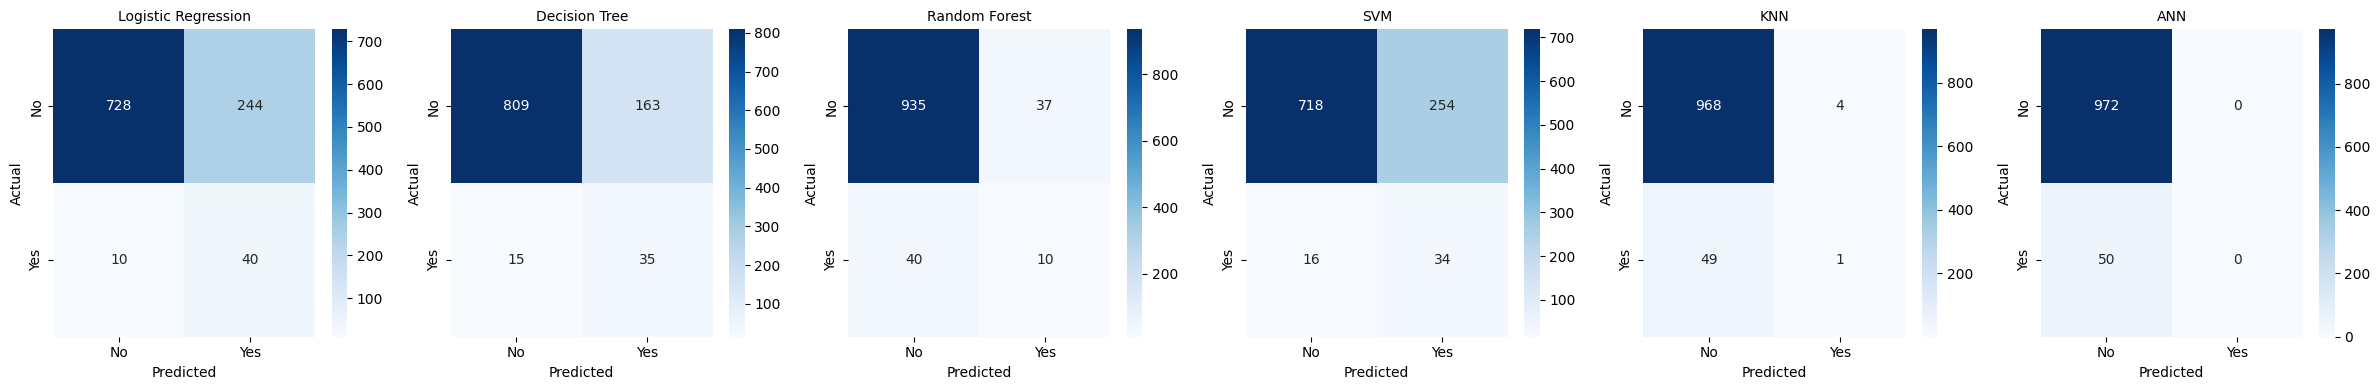

In [ ]:
# ============================================================
# 16. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 6, figsize=(24, 4))

for i, name in enumerate(predictions):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    axes[i].set_title(name, fontsize=10)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

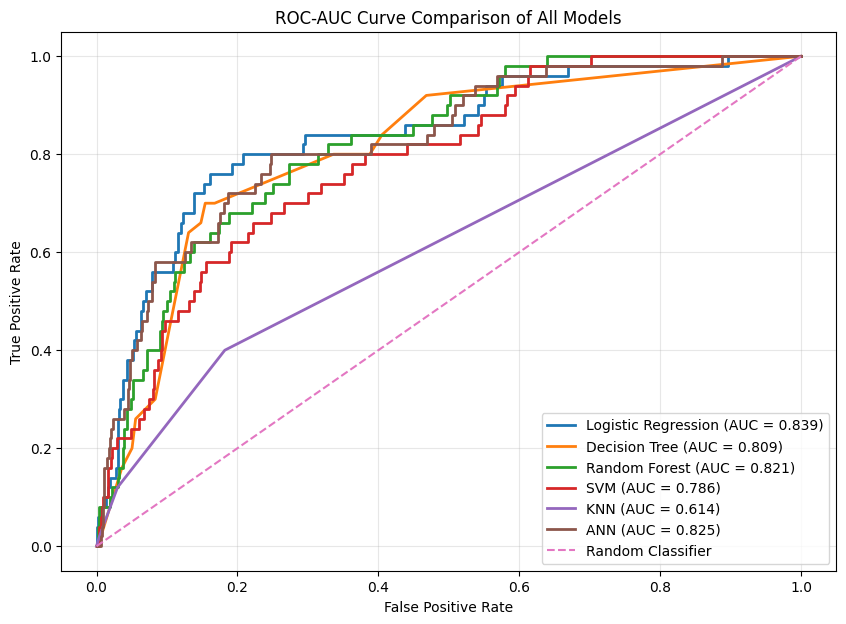

In [ ]:
# ============================================================
# 17. ROC-AUC CURVES
# ============================================================

plt.figure(figsize=(10, 7))

for name in probabilities:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC-AUC Curve Comparison of All Models"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ============================================================
# 18. TOP 3 MODELS
# ============================================================

top3 = results_df.head(3)

print("TOP 3 MODELS FOR STROKE RISK PREDICTION")
print("=" * 80)

display(
    top3.style
    .format("{:.4f}")
    .background_gradient(cmap="Greens")
)

TOP 3 MODELS FOR STROKE RISK PREDICTION


,Accuracy,Precision,Recall,F1-Score,AUC
Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8387
ANN,0.9511,0.0000,0.0000,0.0000,0.8250
Random Forest,0.9247,0.2128,0.2000,0.2062,0.8205


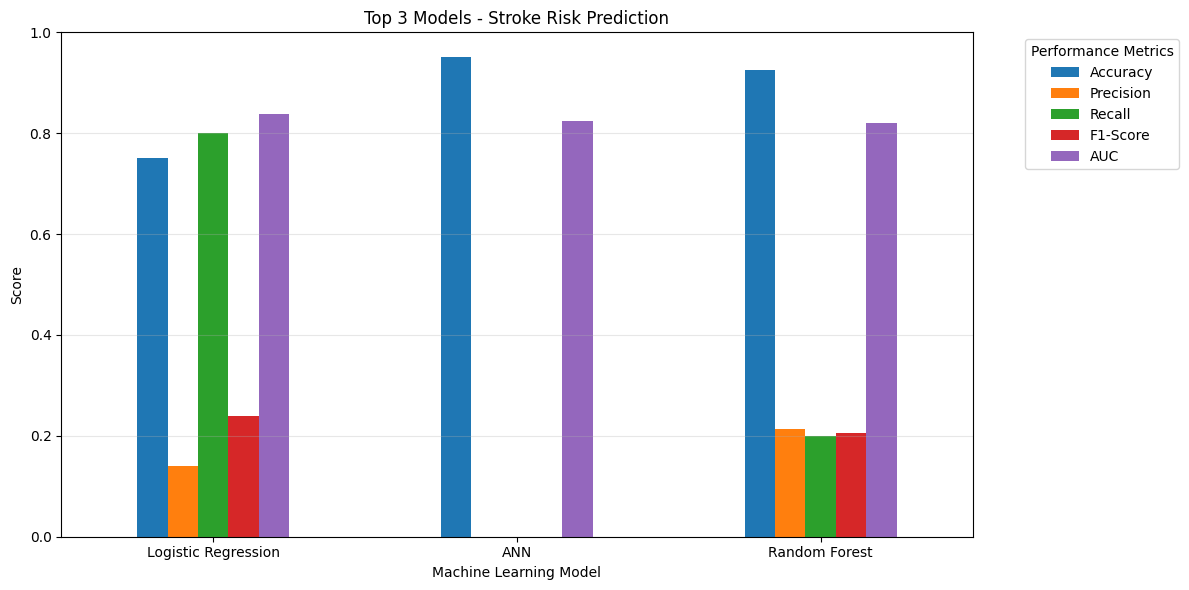

In [ ]:
# ============================================================
# 19. TOP 3 MODEL COMPARISON
# ============================================================

top3.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Top 3 Models - Stroke Risk Prediction"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Score")

plt.xticks(rotation=0)

plt.ylim(0, 1)

plt.legend(
    title="Performance Metrics",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

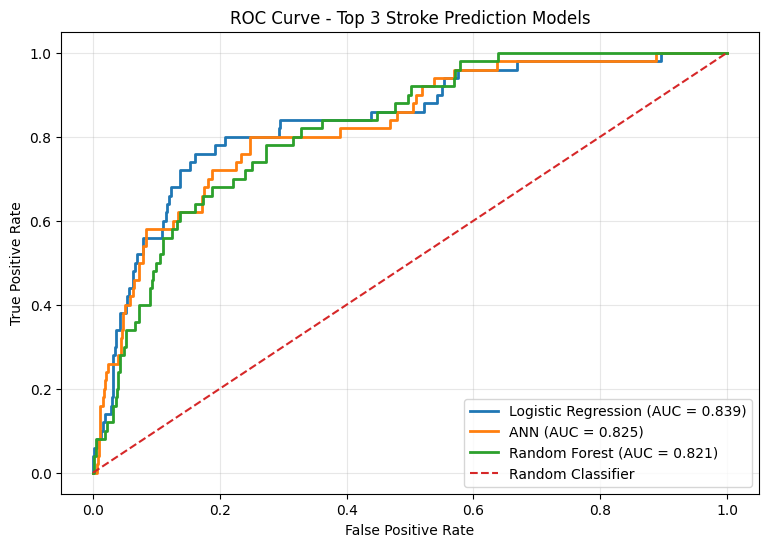

In [ ]:
# ============================================================
# 20. TOP 3 ROC CURVES
# ============================================================

plt.figure(figsize=(9, 6))

for name in top3.index:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Top 3 Stroke Prediction Models"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.show()

In [ ]:
# ============================================================
# 21. BEST MODEL
# ============================================================

best_model = results_df.index[0]

print("=" * 60)
print("BEST MODEL FOR STROKE RISK PREDICTION")
print("=" * 60)

print("Model:", best_model)
print()

print(
    results_df.loc[best_model]
    .round(4)
)

BEST MODEL FOR STROKE RISK PREDICTION
Model: Logistic Regression

Accuracy     0.7515
Precision    0.1408
Recall       0.8000
F1-Score     0.2395
AUC          0.8387
Name: Logistic Regression, dtype: float64


In [ ]:
# ============================================================
# 22. CLASSIFICATION REPORT - TOP 3 MODELS
# ============================================================

for name in top3.index:

    print("\n")
    print("=" * 70)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                "No Stroke",
                "Stroke"
            ],
            zero_division=0
        )
    )



CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.95      0.75      0.82      1022



CLASSIFICATION REPORT: ANN
              precision    recall  f1-score   support

   No Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

   No Stroke       0.96      0.96      0.96       972
      Stroke       0.21      0.20      0.21        50

    accuracy                           0.92      1022
   macro avg   

In [ ]:
# ============================================================
# 23. SAVE RESULTS TO CSV
# ============================================================

results_df.to_csv(
    "stroke_model_comparison_results.csv"
)

top3.to_csv(
    "stroke_top3_models.csv"
)

print("Results saved successfully!")

Results saved successfully!
